# Noise, the Deutsch and the Deutsch–Jozsa algorithms

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Broum/UKP_IQC_materials/blob/main/03_Qiskit_Deutsch.ipynb)

GHZ state on an ideal vs. a noisy simulator &rarr; Deutsch's algorithm &rarr; the Deutsch–Jozsa algorithm.
Run the cells in order (`Shift+Enter`). Every code cell is meant to be edited and re-run.

## 0. Setup

Same as in `01_Qiskit_intro_colab.ipynb`: in Colab the packages are installed per session, so uncomment and re-run
this cell after every runtime restart. For a local conda environment see that notebook.

In [ ]:
# %pip install -q qiskit qiskit-aer pylatexenc matplotlib

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error
from IPython.display import display

print(qiskit.__version__)

2.1.2


## 1. GHZ state: ideal vs. noisy simulator

So far every simulation was *ideal*: gates are exact matrices and the measurement returns exactly what the Born rule says.
Real qubits are not like that. Here we run the same circuit on an ideal simulator and on a simulator with a noise model
typical of today's superconducting qubits, and compare the results.

### 1.1 The GHZ state

The $n$-qubit GHZ (Greenberger–Horne–Zeilinger) state generalises the Bell state:

$$\text{GHZ}_n = \frac{|0\cdots0\rangle + |1\cdots1\rangle}{\sqrt{2}}$$

A Hadamard on $q_0$ followed by a chain of CNOTs copies the superposition onto all qubits.

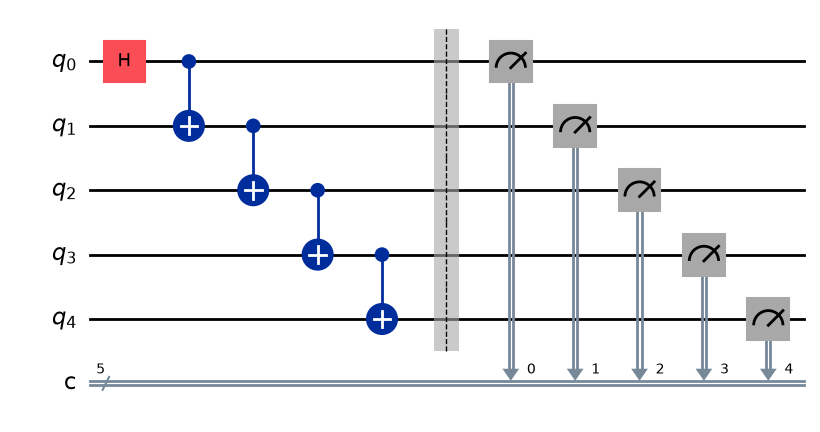

In [ ]:
def ghz_circuit(n: int) -> QuantumCircuit:
    qc = QuantumCircuit(n, n)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    qc.barrier()
    qc.measure(range(n), range(n))
    return qc


n_qubits = 5                           # try 2, 3, 8, ...
qc_ghz = ghz_circuit(n_qubits)
qc_ghz.draw('mpl')

Without the measurement the statevector has amplitudes only on `00…0` and `11…1`:

In [ ]:
Statevector(qc_ghz.remove_final_measurements(inplace=False)).draw('latex')

<IPython.core.display.Latex object>

### 1.2 Ideal simulation

`AerSimulator()` without arguments has no noise. We expect only `00…0` and `11…1`, each in about half of the shots.

{'00000': 2107, '11111': 1989}


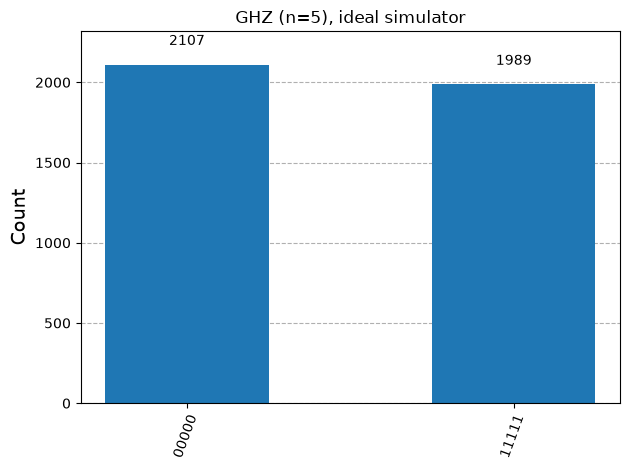

In [ ]:
shots = 4096

ideal_sim = AerSimulator()
counts_ideal = ideal_sim.run(transpile(qc_ghz, ideal_sim), shots=shots).result().get_counts()

print(counts_ideal)
plot_histogram(counts_ideal, title=f'GHZ (n={n_qubits}), ideal simulator')

### 1.3 A noise model for superconducting qubits

A simple, but realistic model. The numbers are **typical orders of magnitude**, real devices differ chip by chip and qubit by qubit.

**Coherence:**
- $T_1 = 80\,\mu s$ (relaxation: how long until $|1\rangle$ decays to $|0\rangle$),
- $T_2 = 60\,\mu s$ (dephasing: how long the relative phase survives). Physically $T_2 \le 2T_1$.

**Gate times** (the longer the gate, the more the qubit decoheres during it):
- 1-qubit gates: $t_{1q} = 35\,ns$,
- 2-qubit gates (CX): $t_{2q} = 250\,ns$.

**Gate errors**, modelled as depolarisation on top of the relaxation:
- 1-qubit: $p_{1q} = 1.0\times10^{-3}$,
- 2-qubit (CX): $p_{2q} = 1.5\times10^{-2}$.

**Readout error:** a measured bit is flipped with probability $2\,\%$.

The model composes thermal relaxation (`thermal_relaxation_error`) with depolarisation (`depolarizing_error`)
and adds a readout error (`add_all_qubit_readout_error`).

In [ ]:
# Coherence and gate times
T1 = 80e-6                             # 80 µs
T2 = 60e-6                             # 60 µs
t_1q = 35e-9                           # 35 ns
t_2q = 250e-9                          # 250 ns

# Depolarising probabilities
p_1q = 1.0e-3
p_2q = 1.5e-2

# Readout error (symmetric)
p_ro = 0.02

noise_model = NoiseModel()

# 1q: thermal relaxation followed by depolarisation
err_1q = thermal_relaxation_error(T1, T2, t_1q).compose(depolarizing_error(p_1q, 1))

# 2q (CX): thermal relaxation on both qubits followed by 2-qubit depolarisation
relax_2q = thermal_relaxation_error(T1, T2, t_2q).tensor(thermal_relaxation_error(T1, T2, t_2q))
err_2q = relax_2q.compose(depolarizing_error(p_2q, 2))

oneq_gates = ['id', 'x', 'y', 'z', 'h', 'sx', 'rx', 'ry', 'rz']
noise_model.add_all_qubit_quantum_error(err_1q, oneq_gates)
noise_model.add_all_qubit_quantum_error(err_2q, ['cx'])

# Readout: row = prepared bit, column = measured bit
noise_model.add_all_qubit_readout_error([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]])

print(noise_model)

NoiseModel:
  Basis gates: ['cx', 'h', 'id', 'rx', 'ry', 'rz', 'sx', 'x', 'y', 'z']
  Instructions with noise: ['id', 'x', 'rz', 'ry', 'sx', 'y', 'h', 'measure', 'cx', 'rx', 'z']
  All-qubits errors: ['id', 'x', 'y', 'z', 'h', 'sx', 'rx', 'ry', 'rz', 'cx', 'measure']


**Noise is attached to gate names.** A gate that is not in the lists above (`mcx`, `ccx`, `swap`, ...) would run *without* noise.
So before a noisy run we transpile the circuit into the gates that carry noise, `basis_gates` below.
On real hardware this happens anyway: the device implements only a few native gates.

In [ ]:
basis_gates = ['cx', 'x', 'sx', 'rz', 'h']
noisy_sim = AerSimulator(noise_model=noise_model)


def run_noisy(qc, shots=shots):
    tqc = transpile(qc, basis_gates=basis_gates)
    return noisy_sim.run(tqc, shots=shots).result().get_counts()

### 1.4 Noisy simulation

The same circuit on the noisy simulator. Besides `00…0` and `11…1` we now see many other bit strings.

{'10100': 1, '01010': 1, '11010': 2, '10001': 1, '01001': 1, '00101': 1, '10011': 2, '01011': 3, '10110': 2, '01110': 2, '01100': 1, '00100': 46, '00000': 1770, '00010': 40, '11111': 1760, '11000': 12, '11110': 62, '10101': 3, '11100': 18, '10111': 47, '00001': 58, '01111': 38, '00110': 3, '01000': 43, '10000': 44, '11011': 50, '00111': 11, '00011': 16, '11101': 58}


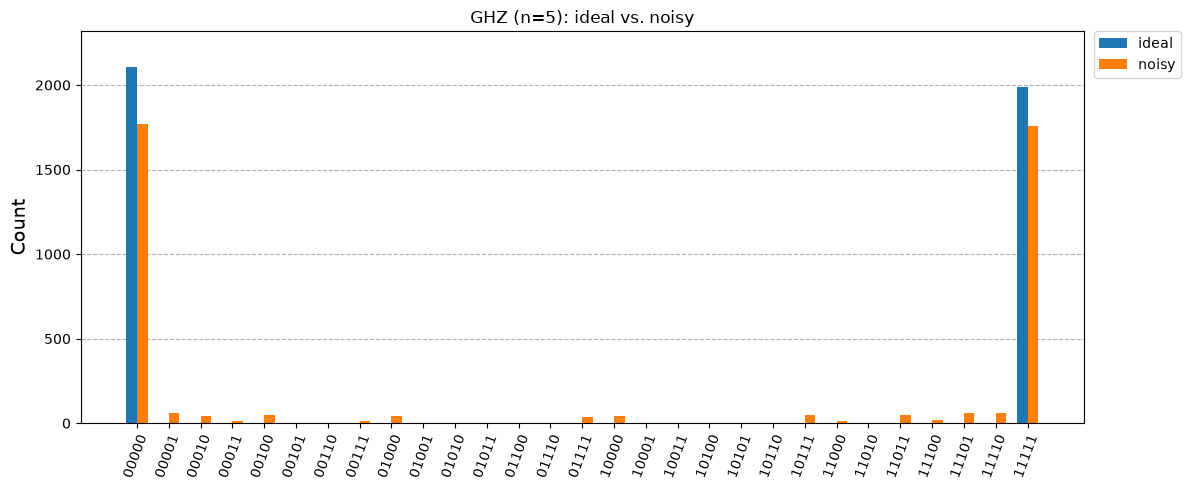

In [ ]:
counts_noisy = run_noisy(qc_ghz)

print(counts_noisy)
plot_histogram([counts_ideal, counts_noisy], legend=['ideal', 'noisy'],
               title=f'GHZ (n={n_qubits}): ideal vs. noisy', figsize=(12, 5), bar_labels=False)

### 1.5 A simple quality metric

The fraction of shots that landed in `00…0` or `11…1`. It is 1 for the ideal simulator.
It is only a rough check: a mixture of `00…0` and `11…1` without any coherence would score 1 as well.

In [ ]:
def ghz_mass(counts, n):
    return (counts.get('0' * n, 0) + counts.get('1' * n, 0)) / sum(counts.values())


print(f'mass on 00..0 and 11..1: ideal {ghz_mass(counts_ideal, n_qubits):.4f}, '
      f'noisy {ghz_mass(counts_noisy, n_qubits):.4f}')

mass on 00..0 and 11..1: ideal 1.0000, noisy 0.8618


### 1.6 Bigger states are more fragile

Every additional qubit adds a CNOT and one more bit that can be misread, so the quality drops with $n$.
Try changing `T1`, `p_2q` or `p_ro` in 1.3 (and re-run 1.3, 1.4 and this cell) to see which error matters most.

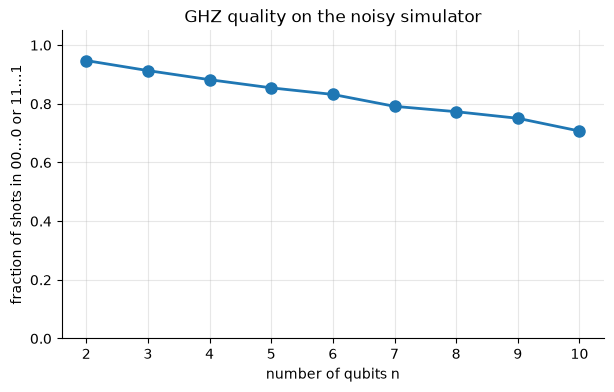

In [ ]:
ns = range(2, 11)
mass = [ghz_mass(run_noisy(ghz_circuit(n)), n) for n in ns]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, mass, marker='o', markersize=8, linewidth=2)
ax.set_ylim(0, 1.05)
ax.set_xlabel('number of qubits n')
ax.set_ylabel('fraction of shots in 00…0 or 11…1')
ax.set_title('GHZ quality on the noisy simulator')
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

## 2. Deutsch's algorithm

**Input:** a function $f:\{0,1\}\rightarrow\{0,1\}$, given as a black box (an *oracle*).

**Question:** is $f$ *constant* ($f(0) = f(1)$) or *balanced* ($f(0) \neq f(1)$)?

Classically we have to evaluate $f$ twice. The quantum algorithm needs **one** query.

There are exactly four such functions:

| case | $f(0)$ | $f(1)$ | $f(x)$ | type |
|---|---|---|---|---|
| 1 | 0 | 0 | $0$ | constant |
| 2 | 0 | 1 | $x$ | balanced |
| 3 | 1 | 0 | $\lnot x$ | balanced |
| 4 | 1 | 1 | $1$ | constant |

### 2.1 The oracle

A quantum gate has to be reversible, so $f$ is encoded as

$$U_f\,|y\rangle|x\rangle = |y \oplus f(x)\rangle|x\rangle$$

with the input $x$ on $q_0$ and the output $y$ on $q_1$ ($\oplus$ is addition mod 2).
`CX(0, 1)` adds $x$ to $y$, `X(1)` adds 1.

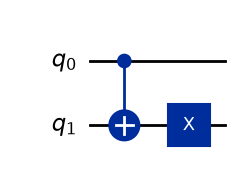

In [ ]:
def deutsch_function(case: int) -> QuantumCircuit:
    # Oracle for one of the 4 functions from one bit to one bit
    if case not in [1, 2, 3, 4]:
        raise ValueError('`case` must be 1, 2, 3, or 4.')

    f = QuantumCircuit(2)
    if case in [2, 3]:
        f.cx(0, 1)
    if case in [3, 4]:
        f.x(1)
    return f


display(deutsch_function(3).draw('mpl'))

The classical way: query the oracle on every input. Prepare $|0\rangle|x\rangle$ (state index $x$), apply the oracle and read $y$:
the output state has index $y\cdot 2^n + x$, so $y$ is the index shifted right by $n$ bits.
The same function works for the $n$-bit oracles in section 3.

In [ ]:
def truth_table(function: QuantumCircuit) -> dict:
    n = function.num_qubits - 1        # input qubits q_0 ... q_{n-1}, output qubit q_n
    table = {}
    for x in range(2**n):
        out = Statevector.from_int(x, 2**(n + 1)).evolve(function)
        table[f'{x:0{n}b}'] = int(np.argmax(out.probabilities())) >> n
    return table


def classify(table: dict) -> str:
    return 'constant' if len(set(table.values())) == 1 else 'balanced'


for case in [1, 2, 3, 4]:
    table = truth_table(deutsch_function(case))
    print(f'case {case}: {table} -> {classify(table)}')

case 1: {'0': 0, '1': 0} -> constant
case 2: {'0': 0, '1': 1} -> balanced
case 3: {'0': 1, '1': 0} -> balanced
case 4: {'0': 1, '1': 1} -> constant


### 2.2 Phase kickback

Prepare the output qubit in $|-\rangle = \frac{1}{\sqrt2}(|0\rangle - |1\rangle)$. Then

$$U_f\,|-\rangle|x\rangle = \frac{|f(x)\rangle - |1\oplus f(x)\rangle}{\sqrt2}|x\rangle = (-1)^{f(x)}|-\rangle|x\rangle$$

The value of $f$ is no longer in $q_1$, it moved into a **phase** of $q_0$. With $q_0$ in $|+\rangle$:

$$U_f\,|-\rangle|+\rangle = |-\rangle\otimes\frac{(-1)^{f(0)}|0\rangle + (-1)^{f(1)}|1\rangle}{\sqrt2}
= \begin{cases} \pm\,|-\rangle|+\rangle & f \text{ constant} \\ \pm\,|-\rangle|-\rangle & f \text{ balanced} \end{cases}$$

The final $H$ turns $|+\rangle \to |0\rangle$ and $|-\rangle \to |1\rangle$, so a single measurement of $q_0$ gives the answer.

### 2.3 The circuit

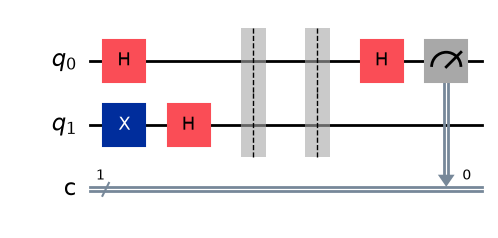

In [ ]:
def deutsch_circuit(function: QuantumCircuit) -> QuantumCircuit:
    qc = QuantumCircuit(2, 1)
    qc.x(1)
    # qc.x(0)  # try what happens with an X on q0 as well, or without the X on q1
    qc.h(0)
    qc.h(1)
    qc.barrier()

    qc.compose(function, inplace=True)

    qc.barrier()
    qc.h(0)
    qc.measure(0, 0)
    return qc


qc = deutsch_circuit(deutsch_function(1))
qc.draw('mpl')

The state of $q_0$ just before the final $H$: $|+\rangle$ for a constant and $|-\rangle$ for a balanced function (up to a global phase).

In [ ]:
for case in [1, 2, 3, 4]:
    sub = QuantumCircuit(2)
    sub.x(1)
    sub.h([0, 1])
    sub.compose(deutsch_function(case), inplace=True)
    display(Statevector(sub).draw('latex', prefix=rf'\text{{case {case}: }}'))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

### 2.4 Run it

One shot = one query of $f$.

In [ ]:
def deutsch_algorithm(function: QuantumCircuit, sim=AerSimulator()) -> str:
    qc = deutsch_circuit(function)
    measurements = sim.run(transpile(qc, sim), shots=1, memory=True).result().get_memory()
    return 'constant' if measurements[0] == '0' else 'balanced'


for case in [1, 2, 3, 4]:
    print(f'case {case}: {deutsch_algorithm(deutsch_function(case))}')

case 1: constant


case 2: balanced


case 3: balanced


case 4: constant


## 3. The Deutsch–Jozsa algorithm

Generalisation of Deutsch's problem to $n$ input bits.

**Input:** a function $f:\{0,1\}^n\rightarrow\{0,1\}$.

**Promise:** $f$ is either constant or balanced (exactly half of the $2^n$ inputs give 1). Other functions are not allowed.

**Output:**
$\begin{cases}
0 & \text{if } f \text{ is constant} \\
1 & \text{if } f \text{ is balanced}
\end{cases}$

A deterministic classical algorithm needs $2^{n-1} + 1$ queries in the worst case (the first half of the inputs can all give
the same value). The quantum algorithm needs **one**.

### 3.1 The oracle for a random function

The oracle acts on $n$ input qubits $q_0,\dots,q_{n-1}$ and one output qubit $q_n$.
With 50 % probability $f$ is constant (output qubit flipped or not), otherwise a random half of the inputs is chosen and,
for each of them, the multi-controlled X flips $q_n$. The X gates around the `mcx` make it fire on that particular
input string instead of on $|1\cdots1\rangle$.

Source: [IBM Quantum Learning, Deutsch–Jozsa algorithm](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/deutsch-jozsa-algorithm)

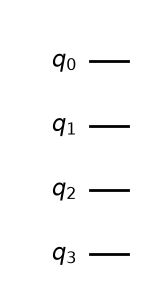

In [ ]:
def dj_query(num_qubits: int) -> QuantumCircuit:
    # Query gate for a random function satisfying the Deutsch-Jozsa promise
    qc = QuantumCircuit(num_qubits + 1)

    if np.random.randint(0, 2):
        # flip the output qubit with 50% chance
        qc.x(num_qubits)
    if np.random.randint(0, 2):
        # return a constant function with 50% chance
        return qc

    # choose half of the possible input strings
    on_states = np.random.choice(
        range(2**num_qubits),          # numbers to sample from
        2**num_qubits // 2,            # number of samples
        replace=False,                 # every state at most once
    )

    def add_cx(qc, bit_string):
        for qubit, bit in enumerate(reversed(bit_string)):
            if bit == '1':
                qc.x(qubit)
        return qc

    for state in on_states:
        qc.barrier()                   # barriers only help to see how the function is built
        qc = add_cx(qc, f'{state:0{num_qubits}b}')
        qc.mcx(list(range(num_qubits)), num_qubits)
        qc = add_cx(qc, f'{state:0{num_qubits}b}')

    qc.barrier()
    return qc


f = dj_query(3)                        # re-run to get another function
f.draw('mpl')

The classical check with `truth_table` from 2.1: $2^n$ queries, we use it only to verify the quantum answer.

In [ ]:
table = truth_table(f)
print(table)
print(classify(table))

{'000': 0, '001': 0, '010': 0, '011': 0, '100': 0, '101': 0, '110': 0, '111': 0}
constant


### 3.2 The circuit

Exactly the structure of Deutsch's algorithm: $|-\rangle$ on the output qubit, $H^{\otimes n}$ on the inputs, one query,
$H^{\otimes n}$ again and measure the inputs.

After the query the inputs are in $\frac{1}{\sqrt{2^n}}\sum_x (-1)^{f(x)}|x\rangle$, and the amplitude of $|0\cdots0\rangle$
after the final $H^{\otimes n}$ is

$$\frac{1}{2^n}\sum_{x\in\{0,1\}^n}(-1)^{f(x)} = \begin{cases} \pm 1 & f \text{ constant} \\ 0 & f \text{ balanced} \end{cases}$$

So a constant $f$ always gives `00…0`, a balanced $f$ **never** gives `00…0`.

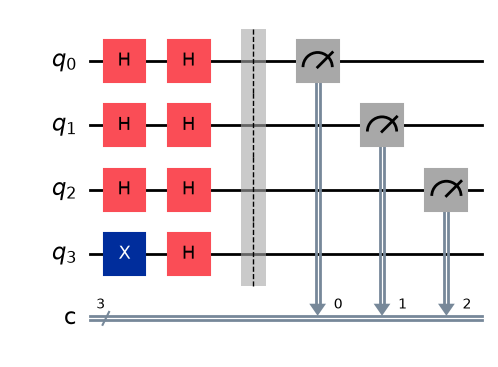

In [ ]:
def compile_circuit(function: QuantumCircuit) -> QuantumCircuit:
    # Wraps the query gate into the Deutsch-Jozsa circuit
    n = function.num_qubits - 1
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    qc.compose(function, inplace=True)
    qc.h(range(n))
    qc.barrier()
    qc.measure(range(n), range(n))
    return qc


compile_circuit(f).draw('mpl', fold=-1)

### 3.3 Run it

In [ ]:
def dj_algorithm(function: QuantumCircuit, sim=AerSimulator()) -> str:
    # Determine if a function is constant or balanced, with a single query
    qc = compile_circuit(function)
    measurements = sim.run(transpile(qc, sim), shots=1, memory=True).result().get_memory()
    return 'balanced' if '1' in measurements[0] else 'constant'


print('quantum, 1 query    :', dj_algorithm(f))
print(f'classical, {2**(f.num_qubits - 1)} queries:', classify(truth_table(f)))

quantum, 1 query    : constant
classical, 8 queries: constant


Many random functions at once: the quantum answer agrees with the truth table every time.

In [ ]:
n = 4
for _ in range(10):
    f = dj_query(n)
    print(f'quantum: {dj_algorithm(f):9s} | classical: {classify(truth_table(f))}')

quantum: balanced  | classical: balanced


quantum: balanced  | classical: balanced
quantum: constant  | classical: constant


quantum: constant  | classical: constant


quantum: balanced  | classical: balanced


quantum: balanced  | classical: balanced


quantum: balanced  | classical: balanced
quantum: constant  | classical: constant


quantum: balanced  | classical: balanced
quantum: constant  | classical: constant


### 3.4 The best classical deterministic algorithm

`truth_table` queries all $2^n$ inputs, more than needed. A deterministic classical algorithm can stop earlier:

- query $f(0), f(1), f(2), \dots$ one input at a time,
- as soon as two values differ, $f$ is **balanced**, stop,
- if the first $2^{n-1} + 1$ values are all equal, $f$ is **constant**: a balanced $f$ has only $2^{n-1}$ zeros and
  $2^{n-1}$ ones, so more than half of the inputs cannot give the same value (the promise).

One query is exactly what `truth_table` does for one input: prepare $|0\rangle|x\rangle$, apply the oracle, read $y$.

In [ ]:
def classical_dj(function: QuantumCircuit) -> tuple[str, int]:
    # Deterministic classical algorithm: query f(0), f(1), ... and stop as soon as the answer is certain.
    # Returns the answer and the number of queries used.
    n = function.num_qubits - 1

    def query(x):
        out = Statevector.from_int(x, 2**(n + 1)).evolve(function)
        return int(np.argmax(out.probabilities())) >> n

    first = query(0)
    for x in range(1, 2**(n - 1) + 1):
        if query(x) != first:
            return 'balanced', x + 1   # queries 0, 1, ..., x
    return 'constant', 2**(n - 1) + 1


n = 4
for _ in range(10):
    f = dj_query(n)
    answer, queries = classical_dj(f)
    print(f'classical: {answer:9s} after {queries:2d} queries | quantum: {dj_algorithm(f):9s} after 1 query')

classical: balanced  after  2 queries | quantum: balanced  after 1 query
classical: constant  after  9 queries | quantum: constant  after 1 query
classical: constant  after  9 queries | quantum: constant  after 1 query


classical: constant  after  9 queries | quantum: constant  after 1 query
classical: constant  after  9 queries | quantum: constant  after 1 query
classical: constant  after  9 queries | quantum: constant  after 1 query


classical: balanced  after  5 queries | quantum: balanced  after 1 query
classical: balanced  after  4 queries | quantum: balanced  after 1 query


classical: constant  after  9 queries | quantum: constant  after 1 query
classical: constant  after  9 queries | quantum: constant  after 1 query


A random balanced function usually gives two different values within the first few queries. The cost is high for a
**constant** function, and for the worst balanced function, which is 0 on the whole first half of the inputs:
$f(x) = x_{n-1}$, the most significant bit. Its oracle is a single CNOT from $q_{n-1}$ to the output qubit.

In [ ]:
for n in range(1, 11):
    f_worst = QuantumCircuit(n + 1)
    f_worst.cx(n - 1, n)               # f(x) = x_{n-1}: 0 for x < 2^(n-1), 1 otherwise
    answer, queries = classical_dj(f_worst)
    print(f'n = {n:2d}: classical {answer} after {queries:3d} queries | quantum {dj_algorithm(f_worst)} after 1 query')

n =  1: classical balanced after   2 queries | quantum balanced after 1 query
n =  2: classical balanced after   3 queries | quantum balanced after 1 query
n =  3: classical balanced after   5 queries | quantum balanced after 1 query


n =  4: classical balanced after   9 queries | quantum balanced after 1 query
n =  5: classical balanced after  17 queries | quantum balanced after 1 query
n =  6: classical balanced after  33 queries | quantum balanced after 1 query


n =  7: classical balanced after  65 queries | quantum balanced after 1 query
n =  8: classical balanced after 129 queries | quantum balanced after 1 query


n =  9: classical balanced after 257 queries | quantum balanced after 1 query
n = 10: classical balanced after 513 queries | quantum balanced after 1 query


The classical worst case grows as $2^{n-1} + 1$, exponentially in $n$, while the quantum algorithm always needs one query.

**But:** this advantage holds only against algorithms that must be correct **with certainty**. A *randomised* classical
algorithm queries $k$ random inputs and answers "balanced" if they differ, "constant" otherwise. It is wrong only for a
balanced $f$ whose $k$ random values all happen to agree, with probability $2\cdot(1/2)^k = 2^{1-k}$: about $0.2\,\%$ for
$k = 10$, independently of $n$. Problems with a stronger quantum advantage are Bernstein–Vazirani and Simon's problem.

### 3.5 Deutsch–Jozsa on the noisy simulator

On an ideal simulator one shot is enough, the answer is certain. With noise this is no longer true: a constant function can
give a string other than `00…0`, and a balanced one can give `00…0`. We run the circuit many times on the noisy simulator
from section 1 and look at the distribution.

The oracle of a balanced function is built from many `mcx` gates, and every `mcx` decomposes into many CNOTs, the noisiest gate
in our model. Compare the number of CNOTs with the GHZ circuit.

constant        truth: constant  | CX gates:   0 | P(000) = 0.936
balanced, 1 CX  truth: balanced  | CX gates:   1 | P(000) = 0.031
balanced, mcx   truth: balanced  | CX gates:  56 | P(000) = 0.102


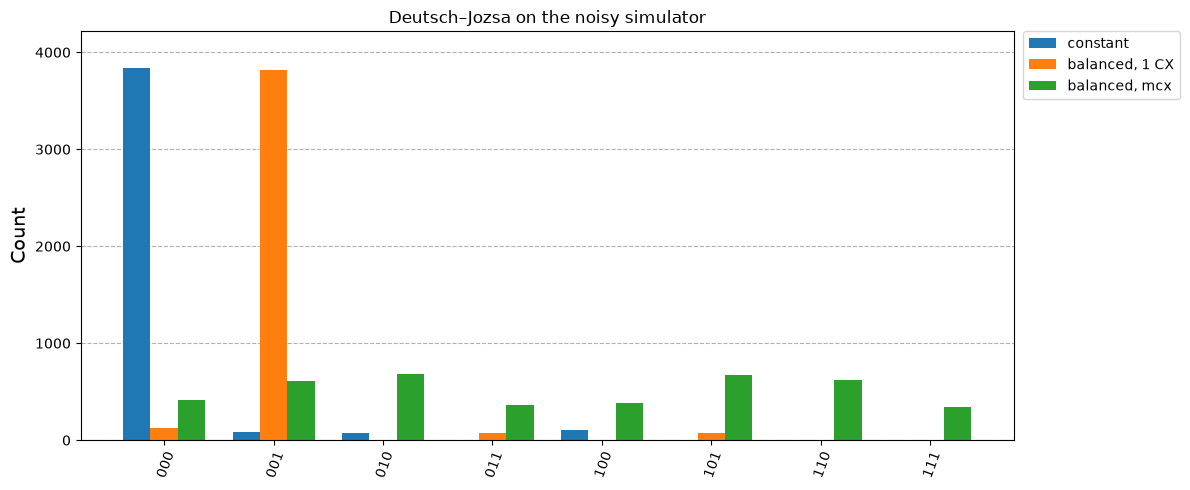

In [ ]:
n = 3
f_const = QuantumCircuit(n + 1)        # f(x) = 0
f_bal = QuantumCircuit(n + 1)          # f(x) = x_0, the cheapest balanced function: one CNOT
f_bal.cx(0, n)
f_mcx = dj_query(n)                    # a random balanced function built from mcx gates
while classify(truth_table(f_mcx)) == 'constant':
    f_mcx = dj_query(n)

results = {}
for name, function in [('constant', f_const), ('balanced, 1 CX', f_bal), ('balanced, mcx', f_mcx)]:
    qc = compile_circuit(function)
    tqc = transpile(qc, basis_gates=basis_gates)
    counts = run_noisy(qc)
    results[name] = counts
    print(f'{name:15s} truth: {classify(truth_table(function)):9s} | CX gates: {tqc.count_ops().get("cx", 0):3d} '
          f'| P(000) = {counts.get("0" * n, 0) / shots:.3f}')

plot_histogram(list(results.values()), legend=list(results.keys()),
               title='Deutsch–Jozsa on the noisy simulator', figsize=(12, 5), bar_labels=False)

**Questions**

- How many shots would you need on the noisy simulator to decide reliably? Is the algorithm still "one query"?
- Why does the constant function suffer less from noise than the random balanced one?
- In 3.1 every input string gets its own `mcx`. Can you write a cheaper oracle for a balanced function (hint: `f_bal`)?